## 타이타닉 생존 여부 예측

승객의 나이·탑승 요금·동반 가족 수·객실 등급·성별·출항지로 생존 여부를 예측한다. 한 행은 승객 한 명이며, 정답 `survived`는 생존 1, 사망 0이다.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

SEED = 42


### 데이터 준비


In [2]:
titanic = sns.load_dataset("titanic")
numeric_columns = ["age", "fare", "sibsp", "parch"]
category_columns = ["pclass", "sex", "embarked"]
X = titanic[numeric_columns + category_columns].copy()
y = titanic["survived"].copy()

print("X:", X.shape, "y:", y.shape)
display(pd.concat([X, y], axis=1).head())
display(X.isna().sum().rename("missing_count"))


X: (891, 7) y: (891,)


,age,fare,sibsp,parch,pclass,sex,embarked,survived
0,22.0,7.2500,1,0,3,male,S,0
1,38.0,71.2833,1,0,1,female,C,1
2,26.0,7.9250,0,0,3,female,S,1
3,35.0,53.1000,1,0,1,female,S,1
4,35.0,8.0500,0,0,3,male,S,0


age         177
fare          0
sibsp         0
parch         0
pclass        0
sex           0
embarked      2
Name: missing_count, dtype: int64

### 학습·검증·테스트 분리


In [3]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=SEED,
)

display(pd.DataFrame([
    {"split": name, "rows": len(labels), "survival_rate": labels.mean()}
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]
]))


,split,rows,survival_rate
0,train,534,0.383895
1,validation,178,0.382022
2,test,179,0.385475


### 결측값 처리와 입력 변환


In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
category_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("category", category_pipeline, category_columns),
])
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

display(pd.DataFrame(
    X_train_processed,
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index,
).head())
print("전처리 후 학습 입력:", X_train_processed.shape)


,numeric__age,numeric__fare,numeric__sibsp,numeric__parch,category__pclass_1,category__pclass_2,category__pclass_3,category__sex_female,category__sex_male,category__embarked_C,category__embarked_Q,category__embarked_S
577,0.692635,0.534937,0.468453,-0.471728,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
63,-1.976834,-0.072617,2.328332,1.860706,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
424,-0.909046,-0.239423,0.468453,0.694489,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
513,1.836693,0.610881,0.468453,-0.471728,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
610,0.692635,0.000615,0.468453,5.359356,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0


전처리 후 학습 입력: (534, 12)


### 기본 로지스틱 회귀와 분류 지표


In [5]:
basic_model = LogisticRegression(C=1.0, max_iter=1000)
basic_model.fit(X_train_processed, y_train)
basic_prediction = basic_model.predict(X_val_processed)


def classification_metrics(actual, predicted):
    return {
        "accuracy": accuracy_score(actual, predicted),
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "f1": f1_score(actual, predicted, zero_division=0),
    }


display(pd.DataFrame({
    "train": classification_metrics(y_train, basic_model.predict(X_train_processed)),
    "validation": classification_metrics(y_val, basic_prediction),
}).T)


,accuracy,precision,recall,f1
train,0.794007,0.743590,0.707317,0.725000
validation,0.792135,0.746032,0.691176,0.717557


### 기본 모델의 혼동 행렬

FP는 사망자를 생존으로 예측한 건수, FN은 생존자를 사망으로 예측한 건수다.


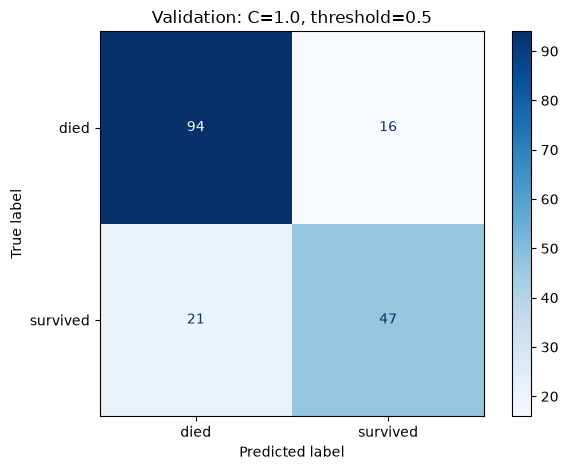

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_val, basic_prediction, labels=[0, 1],
    display_labels=["died", "survived"], cmap="Blues",
)
plt.title("Validation: C=1.0, threshold=0.5")
plt.tight_layout()
plt.show()


## 추가 실험

### 규제 강도 비교

같은 입력과 임계값 0.5에서 `C=1.0·0.5·0.1`을 비교한다. 학습·검증 F1과 기본 모델에서 예측 클래스가 바뀐 사례 수를 함께 확인한다.


In [7]:
models = {1.0: basic_model}
for c_value in [0.5, 0.1]:
    model = LogisticRegression(C=c_value, max_iter=1000)
    model.fit(X_train_processed, y_train)
    models[c_value] = model

regularization_rows = []
for c_value, model in models.items():
    prediction = model.predict(X_val_processed)
    regularization_rows.append({
        "C": c_value,
        "train_f1": f1_score(y_train, model.predict(X_train_processed), zero_division=0),
        "val_f1": f1_score(y_val, prediction, zero_division=0),
        "changed_predictions": int((prediction != basic_prediction).sum()),
    })
regularization_comparison = pd.DataFrame(regularization_rows)
display(regularization_comparison)


,C,train_f1,val_f1,changed_predictions
0,1.0,0.725000,0.717557,0
1,0.5,0.727273,0.723077,1
2,0.1,0.724936,0.728682,2


### 규제 강도 비교 결과

실행 결과, 임계값 0.5에서 `C`를 1.0에서 0.1로 줄이면 검증 F1은 약 0.718에서 0.729로 높아진다. 이때 FP는 16건에서 14건으로 줄고 FN은 21건으로 같다.


### 숫자 입력에 2차항 추가

나이·탑승 요금·동반 가족 수에 원래 항·제곱항·두 변수의 곱을 사용한다. 결측값을 채운 뒤 다항 특성을 만들고 표준화하며, 범주형 입력은 기존 방식으로 처리한다. 같은 분할에서 `C=1.0`, 임계값 0.5를 유지해 기본 모델과 비교한다.


In [8]:
polynomial_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
    ]), numeric_columns),
    ("category", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), category_columns),
])
X_train_polynomial = polynomial_preprocessor.fit_transform(X_train)
X_val_polynomial = polynomial_preprocessor.transform(X_val)

polynomial_model = LogisticRegression(C=1.0, max_iter=1000)
polynomial_model.fit(X_train_polynomial, y_train)

polynomial_rows = []
for name, model, train_input, val_input in [
    ("basic", basic_model, X_train_processed, X_val_processed),
    ("polynomial", polynomial_model, X_train_polynomial, X_val_polynomial),
]:
    train_metrics = classification_metrics(y_train, model.predict(train_input))
    val_metrics = classification_metrics(y_val, model.predict(val_input))
    polynomial_rows.append({
        "model": name, "features": train_input.shape[1],
        "train_f1": train_metrics["f1"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
    })
polynomial_comparison = pd.DataFrame(polynomial_rows)
display(polynomial_comparison)


,model,features,train_f1,val_precision,val_recall,val_f1
0,basic,12,0.72500,0.746032,0.691176,0.717557
1,polynomial,22,0.75063,0.784615,0.750000,0.766917


### 2차항 추가 결과

특성 수는 12개에서 22개로 늘고, 학습 F1은 약 0.725에서 0.751로, 검증 F1은 약 0.718에서 0.767로 높아졌다. 검증 정밀도는 약 0.746에서 0.785로, 재현율은 약 0.691에서 0.750으로 높아졌다. 이번 비교에서는 2차항을 추가했을 때 학습 F1과 검증 F1이 함께 높아졌다.


### 생존 확률과 임계값 비교

각 모델의 생존 확률에 임계값 0.5·0.3·0.7을 적용한다.


In [9]:
candidates = {}
for c_value, model in models.items():
    candidates[f"basic_C{c_value:g}"] = (
        model, preprocessor, X_train_processed, X_val_processed,
    )
candidates["polynomial_C1"] = (
    polynomial_model, polynomial_preprocessor,
    X_train_polynomial, X_val_polynomial,
)

thresholds = [0.5, 0.3, 0.7]
validation_scores = {}
comparison_rows = []
for name, (model, transformer, train_input, val_input) in candidates.items():
    positive_column = list(model.classes_).index(1)
    scores = model.predict_proba(val_input)[:, positive_column]
    validation_scores[name] = scores
    for threshold in thresholds:
        prediction = (scores > threshold).astype(int)
        # labels=[0, 1]인 2×2 혼동 행렬을 행 순서로 펼치면 TN, FP, FN, TP다.
        tn, fp, fn, tp = confusion_matrix(y_val, prediction, labels=[0, 1]).ravel()
        comparison_rows.append({
            "model": name, "C": model.C, "threshold": threshold,
            **classification_metrics(y_val, prediction),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        })

comparison = pd.DataFrame(comparison_rows)
display(comparison)


,model,C,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP
0,basic_C1,1.0,0.5,0.792135,0.746032,0.691176,0.717557,94,16,21,47
1,basic_C1,1.0,0.3,0.775281,0.662791,0.838235,0.740260,81,29,11,57
2,basic_C1,1.0,0.7,0.797753,0.847826,0.573529,0.684211,103,7,29,39
3,basic_C0.5,0.5,0.5,0.797753,0.758065,0.691176,0.723077,95,15,21,47
4,basic_C0.5,0.5,0.3,0.775281,0.662791,0.838235,0.740260,81,29,11,57
5,basic_C0.5,0.5,0.7,0.792135,0.844444,0.558824,0.672566,103,7,30,38
6,basic_C0.1,0.1,0.5,0.803371,0.770492,0.691176,0.728682,96,14,21,47
7,basic_C0.1,0.1,0.3,0.769663,0.658824,0.823529,0.732026,81,29,12,56
8,basic_C0.1,0.1,0.7,0.747191,0.870968,0.397059,0.545455,106,4,41,27
9,polynomial_C1,1.0,0.5,0.825843,0.784615,0.750000,0.766917,96,14,17,51


### 기본 모델의 임계값별 혼동 행렬


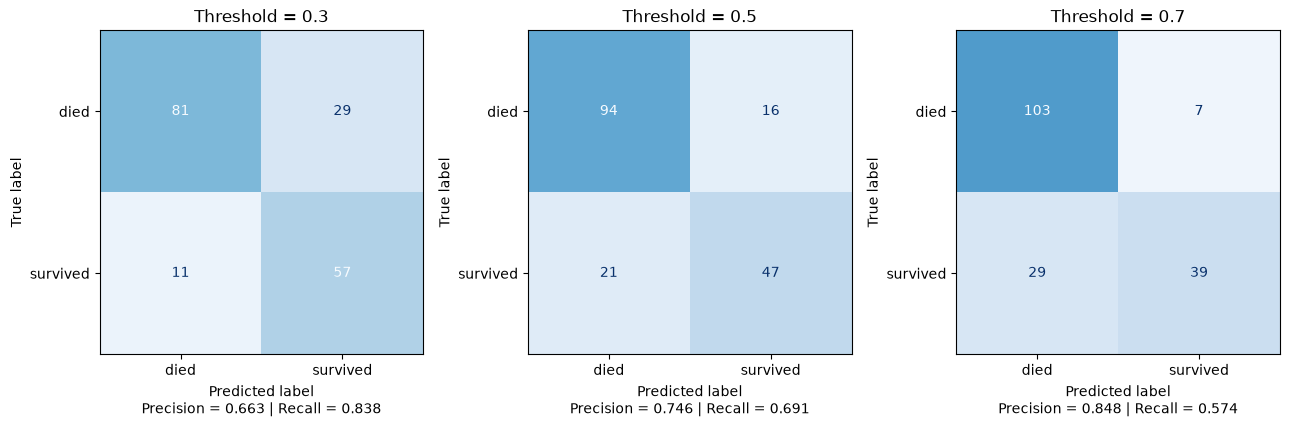

In [10]:
plot_thresholds = [0.3, 0.5, 0.7]
fig, axes = plt.subplots(1, len(plot_thresholds), figsize=(13, 4.5))
for ax, threshold in zip(axes, plot_thresholds):
    prediction = (validation_scores["basic_C1"] > threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_val, prediction, labels=[0, 1], display_labels=["died", "survived"],
        ax=ax, colorbar=False, cmap="Blues", im_kw={"vmin": 0, "vmax": len(y_val)},
    )
    metrics = classification_metrics(y_val, prediction)
    ax.set_title(f"Threshold = {threshold:.1f}")
    ax.set_xlabel(
        f"Predicted label\nPrecision = {metrics['precision']:.3f} | Recall = {metrics['recall']:.3f}"
    )
plt.tight_layout()
plt.show()


### 임계값 비교 결과

기본 모델에서 임계값을 0.5에서 0.3으로 낮추면 FN은 21건에서 11건으로 줄고 FP는 16건에서 29건으로 늘어난다. 정밀도는 약 0.746에서 0.663으로 낮아지고 재현율은 약 0.691에서 0.838로 높아진다. 기본 입력 후보에서는 `C=1.0`과 `C=0.5`의 임계값 0.3이 검증 F1 약 0.740으로 공동 최고다.


### 최종 설정 선택

기본 입력과 2차 다항 입력의 후보 중 검증 F1이 가장 높은 모델과 임계값을 선택한다. 동점이면 비교 표에서 먼저 나온 설정을 사용한다.

2차 다항 입력까지 포함하면 `polynomial_C1`의 임계값 0.5가 검증 F1 약 0.767로 가장 높다. 이 모델과 임계값을 최종 설정으로 선택한다.


In [11]:
selected_index = comparison["f1"].idxmax()
selected_name = comparison.loc[selected_index, "model"]
selected_threshold = float(comparison.loc[selected_index, "threshold"])
selected_model, selected_preprocessor, selected_train_input, selected_val_input = candidates[selected_name]
print(f"최종 설정: {selected_name}, 임계값={selected_threshold:g}")
display(comparison.loc[[selected_index]])

selected_scores = validation_scores[selected_name]
validation_results = X_val.copy()
validation_results["actual_survived"] = y_val
validation_results["survival_probability"] = selected_scores
validation_results["predicted_survived"] = (selected_scores > selected_threshold).astype(int)
display(validation_results.head())


최종 설정: polynomial_C1, 임계값=0.5


,model,C,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP
9,polynomial_C1,1.0,0.5,0.825843,0.784615,0.75,0.766917,96,14,17,51


,age,fare,sibsp,parch,pclass,sex,embarked,actual_survived,survival_probability,predicted_survived
320,22.0,7.2500,0,0,3,male,S,0,0.107693,0
131,20.0,7.0500,0,0,3,male,S,0,0.117699,0
316,24.0,26.0000,1,0,2,female,S,1,0.770941,1
89,24.0,8.0500,0,0,3,male,S,0,0.099056,0
154,NaN,7.3125,0,0,3,male,S,0,0.080992,0


### 최종 테스트


,accuracy,precision,recall,f1
train,0.814607,0.776042,0.726829,0.750630
test,0.787709,0.746032,0.681159,0.712121


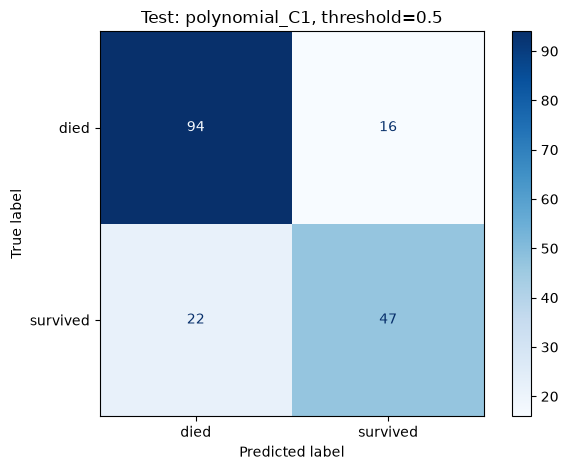

In [12]:
X_test_processed = selected_preprocessor.transform(X_test)
positive_column = list(selected_model.classes_).index(1)
test_scores = selected_model.predict_proba(X_test_processed)[:, positive_column]
test_prediction = (test_scores > selected_threshold).astype(int)
train_scores = selected_model.predict_proba(selected_train_input)[:, positive_column]
train_prediction = (train_scores > selected_threshold).astype(int)

display(pd.DataFrame({
    "train": classification_metrics(y_train, train_prediction),
    "test": classification_metrics(y_test, test_prediction),
}).T)
ConfusionMatrixDisplay.from_predictions(
    y_test, test_prediction, labels=[0, 1],
    display_labels=["died", "survived"], cmap="Blues",
)
plt.title(f"Test: {selected_name}, threshold={selected_threshold:g}")
plt.tight_layout()
plt.show()
